<a href="https://colab.research.google.com/github/contreras-juan/procesamiento_lenguaje_natural/blob/main/Cuadernos/15_CNN_Texto.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 style="color: #FECB05; text-align: center;">Redes convolucionales para texto</h1>

<h2 style="color: #007ACC;">Autores</h2>

- [Juan Felipe Contreras Alcívar](https://www.linkedin.com/in/juanf-contreras/)

---

<h2 style="color: #007ACC;">Tabla de contenido</h2>

- [<span style="color: #005C99;">Introducción</span>](#introduccion)
- [<span style="color: #005C99;">Convoluciones 1D</span>](#convoluciones-1d)
- [<span style="color: #005C99;">Pooling sobre secuencias</span>](#pooling-sobre-secuencias)
- [<span style="color: #005C99;">Clasificación de texto con CNN</span>](#clasificacion-de-texto-con-cnn)
- [<span style="color: #005C99;">¿Qué aprenden los filtros?</span>](#que-aprenden-los-filtros)
- [<span style="color: #005C99;">Comparación con RNN</span>](#comparacion-con-rnn)
- [<span style="color: #005C99;">Referencias</span>](#referencias)

---

<h2 style="color: #007ACC;">Instalación de librerías</h2>

Ejecuta esta celda si trabajas en Google Colab o en un entorno nuevo.

In [1]:
# Instalación de librerías necesarias para esta sesión
# (útil en Google Colab o en un entorno nuevo)
%pip install -q numpy pandas matplotlib tensorflow datasets

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # oculta mensajes informativos de TensorFlow

import re
import string
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)  # fija las semillas de Python, NumPy y TensorFlow

<a id="introduccion"></a>
<h2 style="color: #007ACC;">Introducción</h2>

En el curso de Aprendizaje Profundo, las **redes convolucionales** (CNN) se usaron con imágenes: un filtro pequeño recorre la imagen y responde a un patrón local (un borde, una textura) sin importar dónde aparezca. Con texto la idea es la misma, en **una dimensión**: un filtro recorre la secuencia de embeddings y responde a un patrón de $k$ palabras consecutivas. En otras palabras, un filtro convolucional es un **detector de N-gramas aprendido**.

| | N-gramas (módulo 2) | Convolución 1D |
|---|---|---|
| Unidad | N-grama exacto (*"no es bueno"*) | Ventana de $k$ embeddings |
| Generalización | Ninguna: *"no es bueno"* y *"no es bonito"* son rasgos distintos | Palabras con embeddings parecidos activan el mismo filtro |
| Número de rasgos | Crece con el vocabulario ($|V|^k$) | Fijo: el número de filtros |

Kim (2014) mostró que una CNN de una sola capa sobre embeddings preentrenados igualaba o superaba a modelos mucho más complejos en clasificación de oraciones. Desde entonces las CNN son una opción **rápida** para clasificar texto: a diferencia de las RNN, procesan todas las posiciones **en paralelo**.

En este cuaderno:

1. Implementamos la convolución 1D y el *pooling* a mano.
2. Entrenamos varias CNN para el sentimiento de reseñas de Amazon (la tarea de los cuadernos 11 y 13).
3. Inspeccionamos qué N-gramas detectan los filtros.
4. Comparamos con las RNN en exactitud, velocidad y manejo del orden.

<a id="convoluciones-1d"></a>
<h2 style="color: #007ACC;">Convoluciones 1D</h2>

Sea una oración de $T$ palabras representada por sus embeddings $\mathbf{x}_1, \dots, \mathbf{x}_T \in \mathbb{R}^d$. Un filtro de ancho $k$ es una matriz $W \in \mathbb{R}^{k \times d}$ con un sesgo $b$. Su salida en la posición $t$ es

$$c_t = \text{ReLU}\Big( \sum_{j=0}^{k-1} W_j \cdot \mathbf{x}_{t+j} + b \Big),$$

es decir, el producto punto entre el filtro y la ventana de $k$ palabras que empieza en $t$. Con $m$ filtros se obtiene una matriz de $(T - k + 1) \times m$: un **mapa de activación** por filtro.

Empecemos con un ejemplo hecho a mano. Usamos embeddings *one-hot* (cada dimensión es una palabra) y diseñamos dos filtros de ancho 2: uno que detecta *"es bueno"* y otro que detecta *"no es"*.

In [3]:
vocab = ["el", "producto", "no", "es", "bueno", "malo"]
E = np.eye(len(vocab))  # embeddings one-hot: d = 6


def embeber(frase):
    return E[[vocab.index(p) for p in frase.split()]]


def conv1d(X, W, b):
    """X: (T, d); W: (k, d, m); b: (m,). Convolución 'valid' seguida de ReLU."""
    k = W.shape[0]
    T = X.shape[0]
    return np.maximum(0, np.stack([np.einsum("kd,kdm->m", X[t:t + k], W) for t in range(T - k + 1)]) + b)


W = np.zeros((2, len(vocab), 2))
W[0, vocab.index("es"), 0] = W[1, vocab.index("bueno"), 0] = 1   # filtro 0: "es bueno"
W[0, vocab.index("no"), 1] = W[1, vocab.index("es"), 1] = 1      # filtro 1: "no es"
b = np.array([-1.0, -1.0])  # solo se activa si las DOS palabras coinciden

for frase in ["el producto es bueno", "el producto no es bueno"]:
    palabras = frase.split()
    ventanas = [" ".join(palabras[t:t + 2]) for t in range(len(palabras) - 1)]
    print(frase)
    print(pd.DataFrame(conv1d(embeber(frase), W, b), index=ventanas, columns=["'es bueno'", "'no es'"]), "\n")

el producto es bueno
             'es bueno'  'no es'
el producto         0.0      0.0
producto es         0.0      0.0
es bueno            1.0      0.0 
el producto no es bueno
             'es bueno'  'no es'
el producto         0.0      0.0
producto no         0.0      0.0
no es               0.0      1.0
es bueno            1.0      0.0 


Cada filtro solo se activa en la ventana que contiene su patrón. Un clasificador encima de estos filtros podría aprender que *"es bueno"* sin *"no es"* indica una reseña positiva. Un filtro de ancho 3 podría detectar directamente *"no es bueno"*.

En una red real los filtros **no se diseñan**: se aprenden por descenso del gradiente, y los embeddings no son *one-hot* sino densos, de modo que un filtro que aprende *"es bueno"* también responde a *"es buenísimo"* o *"es excelente"*.

Comprobemos que nuestra implementación coincide con la capa `Conv1D` de Keras (que, como en imágenes, en realidad calcula una correlación cruzada):

In [4]:
rng = np.random.default_rng(SEED)
X = rng.normal(size=(7, 4)).astype("float32")  # 7 palabras, embeddings de dimensión 4
capa = layers.Conv1D(filters=3, kernel_size=3, activation="relu")
salida_keras = capa(X[None])[0].numpy()
W_keras, b_keras = capa.get_weights()
print("Forma de los pesos (k, d, m):", W_keras.shape)
print("Forma de la salida (T - k + 1, m):", salida_keras.shape)
print("¿Coinciden NumPy y Keras?", np.allclose(conv1d(X, W_keras, b_keras), salida_keras, atol=1e-5))

Forma de los pesos (k, d, m): (3, 4, 3)
Forma de la salida (T - k + 1, m): (5, 3)
¿Coinciden NumPy y Keras? True


Algunos hiperparámetros de la convolución:

- **`padding`**: con `"valid"` (por defecto) la salida es más corta que la entrada; con `"same"` se rellenan los bordes para que tenga la misma longitud.
- **`strides`**: cada cuántas posiciones se aplica el filtro.
- **`dilation_rate`**: deja "huecos" dentro del filtro, para cubrir más contexto con los mismos parámetros.

Al **apilar** capas, cada salida "ve" una porción cada vez mayor de la oración. El **campo receptivo** de $L$ capas con anchos $k_\ell$ y dilataciones $d_\ell$ es $r = 1 + \sum_\ell (k_\ell - 1)\, d_\ell$:

In [5]:
def campo_receptivo(anchos, dilataciones=None):
    dilataciones = dilataciones or [1] * len(anchos)
    return 1 + sum((k - 1) * d for k, d in zip(anchos, dilataciones))


pd.DataFrame([
    {"configuración": "1 capa, k = 5", "campo receptivo (palabras)": campo_receptivo([5])},
    {"configuración": "3 capas, k = 3", "campo receptivo (palabras)": campo_receptivo([3, 3, 3])},
    {"configuración": "3 capas, k = 3, dilataciones 1, 2, 4", "campo receptivo (palabras)": campo_receptivo([3, 3, 3], [1, 2, 4])},
    {"configuración": "6 capas, k = 3, dilataciones 1, 2, 4, 8, 16, 32", "campo receptivo (palabras)": campo_receptivo([3] * 6, [1, 2, 4, 8, 16, 32])},
]).set_index("configuración")

,campo receptivo (palabras)
configuración,
"1 capa, k = 5",5
"3 capas, k = 3",7
"3 capas, k = 3, dilataciones 1, 2, 4",15
"6 capas, k = 3, dilataciones 1, 2, 4, 8, 16, 32",127


Con dilataciones que se duplican, el campo receptivo crece **exponencialmente** con la profundidad. Esta es la idea de WaveNet y de las redes convolucionales para traducción (ConvS2S, Gehring et al., 2017), que fueron la principal alternativa a las RNN antes de los Transformers.

<a id="pooling-sobre-secuencias"></a>
<h2 style="color: #007ACC;">Pooling sobre secuencias</h2>

La convolución produce un mapa de activación cuya longitud depende de la oración. Para clasificar necesitamos un vector de tamaño fijo, así que **reducimos la dimensión temporal** con una operación de *pooling*:

- **Max pooling global** (`GlobalMaxPooling1D`): para cada filtro, la activación máxima en toda la oración. Responde a la pregunta *¿aparece el patrón en algún lugar?* Es la opción estándar en clasificación (Kim, 2014; Collobert et al., 2011).
- **Average pooling global** (`GlobalAveragePooling1D`): la activación promedio. Mide *cuánto* aparece el patrón, pero diluye un patrón fuerte que aparece una sola vez en un texto largo.
- **k-max pooling**: los $k$ valores más altos, conservando su orden.
- **Max pooling local** (`MaxPooling1D`): reduce la secuencia por un factor (por ejemplo, de 100 a 33 posiciones) para apilar más convoluciones encima.

Veamos la diferencia entre máximo y promedio con nuestro filtro *"es bueno"* en una reseña corta y en una larga:

In [6]:
vocab += ["llegó", "rápido", "y", "la", "caja", "estaba", "en", "buen", "estado", "pero"]
E = np.eye(len(vocab))
W = np.zeros((2, len(vocab), 1))
W[0, vocab.index("es"), 0] = W[1, vocab.index("bueno"), 0] = 1

corta = "el producto es bueno"
larga = "el producto llegó rápido y la caja estaba en buen estado pero el producto es bueno"
for frase in [corta, larga]:
    mapa = conv1d(embeber(frase), W, np.array([-1.0]))[:, 0]
    print(f"{len(frase.split()):>2} palabras | máximo: {mapa.max():.2f} | promedio: {mapa.mean():.3f}")

 4 palabras | máximo: 1.00 | promedio: 0.333
16 palabras | máximo: 1.00 | promedio: 0.067


El máximo es el mismo en las dos reseñas (el patrón aparece), mientras que el promedio se reduce a la cuarta parte en la reseña larga.

**El relleno.** Para entrenar por lotes, las secuencias se rellenan con el índice 0 hasta una longitud común. A diferencia de las capas recurrentes de Keras, `Conv1D` **no usa máscaras**: las ventanas que contienen relleno también producen activaciones, y el máximo puede venir del relleno. En la práctica la red aprende a que el embedding del relleno no active los filtros importantes. Más adelante medimos con qué frecuencia ocurre.

<a id="clasificacion-de-texto-con-cnn"></a>
<h2 style="color: #007ACC;">Clasificación de texto con CNN</h2>

Usamos los mismos datos y la misma vectorización que en los cuadernos 11 y 13: 60 000 reseñas de Amazon en español para entrenar, sentimiento binario, vocabulario de 20 000 palabras y secuencias de 100 tokens.

In [7]:
from datasets import load_dataset

# Reseñas de Amazon en español: 200 000 de entrenamiento, 5 000 de validación y 5 000 de prueba.
# La etiqueta va de 0 a 4 (de 1 a 5 estrellas).
resenas = load_dataset("SetFit/amazon_reviews_multi_es")


def a_binario(split, n=None):
    """Reseñas negativas (1-2 estrellas) -> 0, positivas (4-5 estrellas) -> 1; se descartan las de 3."""
    df = resenas[split].to_pandas()
    df = df[df.label != 2]
    if n is not None:
        df = df.sample(n=n, random_state=SEED)
    return df.text.tolist(), (df.label >= 3).astype(int).to_numpy()


X_train_txt, y_train = a_binario("train", n=60_000)
X_val_txt, y_val = a_binario("validation")
X_test_txt, y_test = a_binario("test")
print(f"Entrenamiento: {len(X_train_txt)} | Validación: {len(X_val_txt)} | Prueba: {len(X_test_txt)}")
print(f"Proporción de positivas en entrenamiento: {y_train.mean():.2f}")
for texto, etiqueta in zip(X_train_txt[:3], y_train[:3]):
    print(f"[{'positiva' if etiqueta else 'negativa'}] {texto}")

Entrenamiento: 60000 | Validación: 4000 | Prueba: 4000
Proporción de positivas en entrenamiento: 0.50
[positiva] A mi mujer le ha parecido muy bueno, indicando que seca muy bien. A mi me ha parecido de buena construcción y mejor de lo que me esperaba. Y llegó muy puntual. Además es muy sencillo de usar.
[negativa] El equipo no funciona correctamente. Los micrófonos hacen ruido e interfieren en la reproducción del audio. Tienes que estar moviendo continuamente el cable para intentar buscar la posición para que no hagan ruido. No lo usamos
[negativa] Lo compre porque es barato y para salir de viaje está muy bien. El material no es gran cosa y para temperaturas muy bajas no tiene pinta de abrigar. Le doy dos estrellas porque no es gris como en la foto, el que me ha llegado es completamente negro


In [8]:
def estandarizar(texto):
    """Minúsculas y eliminación de puntuación, incluidos los signos de apertura del español."""
    texto = tf.strings.lower(texto)
    return tf.strings.regex_replace(texto, r"[¡¿«»“”\"#$%&()*+,\-./:;<=>?@\[\\\]^_`{|}~!']", " ")

MAX_TOKENS, LONGITUD = 20_000, 100
vectorizador = layers.TextVectorization(max_tokens=MAX_TOKENS, output_sequence_length=LONGITUD, standardize=estandarizar)
vectorizador.adapt(X_train_txt)
vocabulario = np.array(vectorizador.get_vocabulary())
X_train, X_val, X_test = (vectorizador(np.array(t)).numpy() for t in (X_train_txt, X_val_txt, X_test_txt))
print(X_train.shape)

(60000, 100)


Comparamos tres arquitecturas convolucionales:

- **CNN simple:** una capa `Conv1D` de 128 filtros de ancho 5 y max pooling global.
- **CNN multifiltro** (Kim, 2014): filtros de anchos 2, 3, 4 y 5 en paralelo, 64 de cada uno, cada grupo con su max pooling global, y los resultados concatenados. Cada ancho captura N-gramas de distinto tamaño.
- **CNN apilada:** dos convoluciones con un max pooling local en medio, para un campo receptivo de 17 palabras.

```text
                   ┌─ Conv1D(k=2) ─ MaxPool global ─┐
texto → Embedding ─┼─ Conv1D(k=3) ─ MaxPool global ─┼─ concatenar ─ Dropout ─ Dense(1)
                   ├─ Conv1D(k=4) ─ MaxPool global ─┤
                   └─ Conv1D(k=5) ─ MaxPool global ─┘
```

Usamos la API funcional de Keras porque el modelo multifiltro tiene ramas paralelas.

In [9]:
def graficar_historial(historial, titulo="Curvas de entrenamiento"):
    h = historial.history
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    for ax, metrica in zip(axes, ["loss", "accuracy"]):
        ax.plot(h[metrica], marker="o", label="entrenamiento")
        ax.plot(h["val_" + metrica], marker="o", label="validación")
        ax.set_xlabel("época")
        ax.set_title(metrica)
        ax.legend()
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

DIM_EMB = 64


def compilar(entrada, salida):
    modelo = keras.Model(entrada, salida)
    modelo.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return modelo


def cnn_simple():
    entrada = keras.Input(shape=(LONGITUD,), dtype="int64")
    x = layers.Embedding(MAX_TOKENS, DIM_EMB)(entrada)
    x = layers.Conv1D(128, 5, activation="relu")(x)
    x = layers.GlobalMaxPooling1D()(x)
    x = layers.Dropout(0.3)(x)
    return compilar(entrada, layers.Dense(1, activation="sigmoid")(x))


def cnn_multifiltro(anchos=(2, 3, 4, 5), filtros=64):
    entrada = keras.Input(shape=(LONGITUD,), dtype="int64")
    emb = layers.Embedding(MAX_TOKENS, DIM_EMB)(entrada)
    ramas = []
    for k in anchos:
        mapa = layers.Conv1D(filtros, k, activation="relu", name=f"conv_k{k}")(emb)
        ramas.append(layers.GlobalMaxPooling1D()(mapa))
    x = layers.Concatenate(name="rasgos")(ramas)
    x = layers.Dropout(0.5)(x)
    return compilar(entrada, layers.Dense(1, activation="sigmoid", name="salida")(x))


def cnn_apilada():
    entrada = keras.Input(shape=(LONGITUD,), dtype="int64")
    x = layers.Embedding(MAX_TOKENS, DIM_EMB)(entrada)
    x = layers.Conv1D(128, 5, activation="relu")(x)
    x = layers.MaxPooling1D(3)(x)
    x = layers.Conv1D(128, 5, activation="relu")(x)
    x = layers.GlobalMaxPooling1D()(x)
    x = layers.Dropout(0.3)(x)
    return compilar(entrada, layers.Dense(1, activation="sigmoid")(x))


def entrenar(constructor, nombre):
    keras.utils.set_random_seed(SEED)
    modelo = constructor()
    inicio = time.perf_counter()
    historial = modelo.fit(
        X_train, y_train, validation_data=(X_val, y_val), epochs=6, batch_size=256, verbose=0,
        callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=1, restore_best_weights=True)])
    t_entrenamiento = time.perf_counter() - inicio
    inicio = time.perf_counter()
    modelo.predict(X_test, batch_size=512, verbose=0)
    fila = {"modelo": nombre, "parámetros": modelo.count_params(),
            "épocas": len(historial.history["loss"]),
            "tiempo por época (s)": t_entrenamiento / len(historial.history["loss"]),
            "inferencia en prueba (s)": time.perf_counter() - inicio,
            "exactitud en validación": max(historial.history["val_accuracy"]),
            "exactitud en prueba": modelo.evaluate(X_test, y_test, verbose=0)[1]}
    print(f"{nombre:<20} listo")
    return modelo, historial, fila


modelos, historiales, filas = {}, {}, []
for nombre, constructor in [("CNN simple", cnn_simple), ("CNN multifiltro", cnn_multifiltro), ("CNN apilada", cnn_apilada)]:
    modelos[nombre], historiales[nombre], fila = entrenar(constructor, nombre)
    filas.append(fila)

pd.DataFrame(filas).set_index("modelo").round(4)

CNN simple           listo


CNN multifiltro      listo


CNN apilada          listo


,parámetros,épocas,tiempo por época (s),inferencia en prueba (s),exactitud en validación,exactitud en prueba
modelo,,,,,,
CNN simple,1321217,3,2.0823,0.0886,0.9022,0.8963
CNN multifiltro,1337857,3,2.9821,0.1147,0.9010,0.8980
CNN apilada,1403265,3,2.5507,0.1134,0.9007,0.9035


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 100)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 100, 64)   │  1,280,000 │ input_layer_1[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_k2 (Conv1D)    │ (None, 99, 64)    │      8,256 │ embedding_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_k3 (Conv1D)    │ (None, 98, 64)    │     12,352 │ embedding_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_k4 (Conv1D)    │ (None, 97, 64)    │     16,448 │ embedding_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_k5 (Conv1D)    │ (None, 96, 64)    │     20,544 │ embedding_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 64)        │          0 │ conv_k2[0][0]     │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 64)        │          0 │ conv_k3[0][0]     │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 64)        │          0 │ conv_k4[0][0]     │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 64)        │          0 │ conv_k5[0][0]     │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rasgos              │ (None, 256)       │          0 │ global_max_pooli… │
│ (Concatenate)       │                   │            │ global_max_pooli… │
│                     │                   │            │ global_max_pooli… │
│                     │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 256)       │          0 │ rasgos[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ salida (Dense)      │ (None, 1)         │        257 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,013,573 (15.31 MB)

 Trainable params: 1,337,857 (5.10 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,675,716 (10.21 MB)

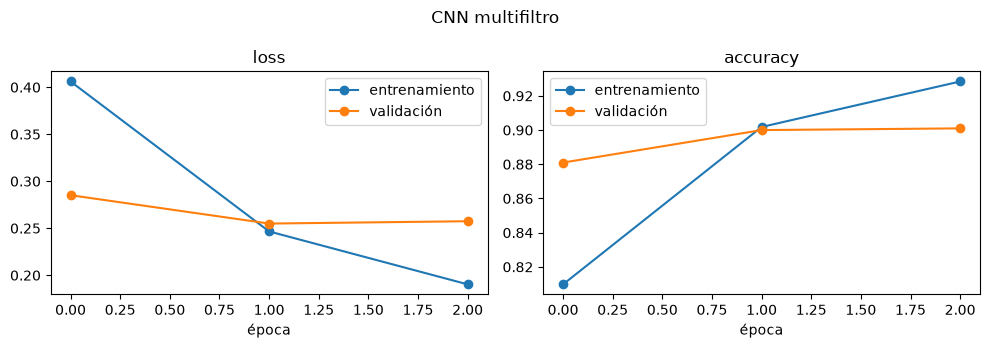

In [10]:
modelos["CNN multifiltro"].summary()
graficar_historial(historiales["CNN multifiltro"], "CNN multifiltro")

Las tres CNN alcanzan una exactitud parecida (entre 89,6 % y 90,4 % en prueba), igual o mejor que la de los modelos recurrentes del cuaderno 13 (entre 88,5 % y 89,8 %), y cada época tarda dos o tres segundos. Como en los modelos anteriores, el sobreajuste aparece después de la primera o segunda época: la mayoría de los parámetros están en la capa de embedding (20 000 × 64 = 1,28 millones), que se aprende desde cero con 60 000 reseñas.

En validación, las tres quedan a menos de 0,2 puntos entre sí. La CNN apilada obtiene el mejor resultado en prueba, pero la diferencia (medio punto) es del orden del error estándar de la exactitud con 4 000 reseñas, $\\sqrt{0{,}9 \\cdot 0{,}1 / 4000} \\approx 0{,}5$ puntos, así que no podemos afirmar que sea mejor. Ampliar el campo receptivo aporta poco porque, en reseñas, el sentimiento depende sobre todo de expresiones locales (*"no funciona"*, *"muy buena calidad"*) que caben en una ventana de 2 a 5 palabras.

<a id="que-aprenden-los-filtros"></a>
<h2 style="color: #007ACC;">¿Qué aprenden los filtros?</h2>

Una ventaja de las CNN de una capa es que son relativamente **interpretables**. Cada rasgo que llega a la capa de salida es el máximo de un filtro sobre la reseña, y la capa de salida le asigna un peso. Los filtros con peso positivo grande empujan hacia *positiva* y los de peso negativo hacia *negativa*.

Para ver qué detecta un filtro, buscamos los N-gramas de las reseñas de validación en los que se activa con más fuerza:

In [11]:
modelo = modelos["CNN multifiltro"]
anchos = [2, 3, 4, 5]
extractor = keras.Model(modelo.input, [modelo.get_layer(f"conv_k{k}").output for k in anchos])
mapas = extractor.predict(X_val, batch_size=512, verbose=0)  # lista de (n_reseñas, T - k + 1, 64)
pesos_salida = modelo.get_layer("salida").get_weights()[0].ravel()  # un peso por rasgo (4 × 64)


def top_ngramas(rama, filtro, n=6):
    k = anchos[rama]
    mapa = mapas[rama][:, :, filtro]
    mejores = np.argsort(mapa.ravel())[::-1]
    vistos, resultado = set(), []
    for indice in mejores:
        resena, pos = np.unravel_index(indice, mapa.shape)
        ngrama = " ".join(vocabulario[X_val[resena, pos:pos + k]]).strip()
        if ngrama and ngrama not in vistos:
            vistos.add(ngrama)
            resultado.append(ngrama)
        if len(resultado) == n:
            break
    return " | ".join(resultado)


tabla = []
for indice in list(np.argsort(pesos_salida)[:4]) + list(np.argsort(pesos_salida)[-4:]):
    rama, filtro = divmod(indice, 64)
    tabla.append({"ancho": anchos[rama], "filtro": filtro, "peso en la salida": pesos_salida[indice],
                  "N-gramas que más lo activan": top_ngramas(rama, filtro)})
pd.set_option("display.max_colwidth", 120)
pd.DataFrame(tabla).round(3)

,ancho,filtro,peso en la salida,N-gramas que más lo activan
0,2,26,-0.255,menuda decepción | devolver apagaba | muy decepcionada | menuda decepcion | menuda basura | devuelto dos
1,2,31,-0.252,menuda decepción | menuda decepcion | devolver apagaba | auténtica estafa | muy decepcionada | bastante decepcionada
2,5,9,-0.249,muy decepcionada con amazon nunca | muy decepcionada con amazon compré | muy descontenta aunque amazon siempre | muy...
3,2,60,-0.246,amazon decepcionante | muy decepcionada | amazon ponia | solicitado devolución | menuda decepcion | conlleva devolución
4,4,48,0.233,buen precio totalmente satisfecho | geniales las recomiendo 100 | buen producto y excelente | buen producto envio co...
5,5,5,0.236,buena calidad estoy contento la | relación calidad precio genial recomendable | buena calidad la recomiendo | buena ...
6,5,1,0.253,buen precio totalmente satisfecho y | buen precio sin duda compraré | buen material sin duda volveré | buen producto...
7,5,7,0.257,perfectamente super contento encantado con | estupendamente bien 100 recomendable producto | muy versátil funciona c...


Los filtros con peso negativo responden a N-gramas de decepción, estafa y devoluciones (*"menuda decepción"*, *"auténtica estafa"*, *"solicitado devolución"*) y los de peso positivo a N-gramas de elogio y recomendación (*"buen precio totalmente satisfecho"*, *"relación calidad precio genial"*). Un mismo filtro agrupa expresiones **distintas pero con un significado parecido**: eso es lo que no podía hacer una bolsa de N-gramas.

Estas listas son una herramienta de diagnóstico, no una explicación completa del modelo: cada filtro responde a muchos patrones a la vez y la decisión combina 256 rasgos.

Midamos también lo que anunciamos sobre el relleno: ¿con qué frecuencia el máximo de un filtro proviene de una ventana que contiene relleno?

In [12]:
longitudes = (X_val != 0).sum(axis=1)
for rama, k in enumerate(anchos):
    posicion_max = mapas[rama].argmax(axis=1)  # (n_reseñas, 64)
    toca_relleno = posicion_max + k > longitudes[:, None]
    cortas = longitudes < 30
    print(f"k = {k}: el máximo incluye relleno en el {toca_relleno.mean():.1%} de los casos "
          f"({toca_relleno[cortas].mean():.1%} en reseñas de menos de 30 palabras)")

k = 2: el máximo incluye relleno en el 6.1% de los casos (7.6% en reseñas de menos de 30 palabras)
k = 3: el máximo incluye relleno en el 8.3% de los casos (10.3% en reseñas de menos de 30 palabras)
k = 4: el máximo incluye relleno en el 12.3% de los casos (15.3% en reseñas de menos de 30 palabras)
k = 5: el máximo incluye relleno en el 14.3% de los casos (18.3% en reseñas de menos de 30 palabras)


Entre el 6 % y el 14 % de las veces, según el ancho del filtro, el máximo viene de una ventana con relleno, y hasta el 18 % en reseñas cortas con filtros anchos (una ventana de 5 palabras toca el relleno más a menudo). Esto no es necesariamente un error: el embedding del relleno es un vector aprendido como cualquier otro, y la red puede usar "fin de la reseña" como una señal (por ejemplo, *"excelente [relleno]"*). Pero significa que el resultado depende de la longitud de relleno elegida. Si eso importa, se pueden multiplicar los mapas de activación por la máscara antes del pooling o agrupar las reseñas por longitud.

<a id="comparacion-con-rnn"></a>
<h2 style="color: #007ACC;">Comparación con RNN</h2>

Entrenamos en las mismas condiciones el modelo de promedio de embeddings y dos modelos recurrentes del cuaderno 13, y comparamos exactitud y velocidad:

In [13]:
def recurrente(nucleo):
    def constructor():
        entrada = keras.Input(shape=(LONGITUD,), dtype="int64")
        x = layers.Embedding(MAX_TOKENS, DIM_EMB, mask_zero=True)(entrada)
        x = nucleo()(x)
        x = layers.Dropout(0.3)(x)
        return compilar(entrada, layers.Dense(1, activation="sigmoid")(x))
    return constructor


for nombre, nucleo in [("Promedio", layers.GlobalAveragePooling1D),
                       ("GRU", lambda: layers.GRU(64)),
                       ("LSTM bidireccional", lambda: layers.Bidirectional(layers.LSTM(64)))]:
    modelos[nombre], historiales[nombre], fila = entrenar(recurrente(nucleo), nombre)
    filas.append(fila)

comparacion = pd.DataFrame(filas).set_index("modelo")
comparacion.round(4)

Promedio             listo


GRU                  listo


LSTM bidireccional   listo


,parámetros,épocas,tiempo por época (s),inferencia en prueba (s),exactitud en validación,exactitud en prueba
modelo,,,,,,
CNN simple,1321217,3,2.0823,0.0886,0.9022,0.8963
CNN multifiltro,1337857,3,2.9821,0.1147,0.9010,0.8980
CNN apilada,1403265,3,2.5507,0.1134,0.9007,0.9035
Promedio,1280065,6,1.1170,0.0654,0.8802,0.8882
GRU,1305025,4,7.5162,0.2959,0.8850,0.8985
LSTM bidireccional,1346177,3,10.4036,0.4377,0.8825,0.8960


La comparación muestra el principal argumento a favor de las CNN: con una exactitud igual o mejor que la de las RNN, cada época tarda 2–3 s frente a 7,5 s de la GRU y 10 s de la LSTM bidireccional, y la inferencia es de 3 a 4 veces más rápida. Todas las posiciones se calculan en paralelo, mientras que una RNN debe procesar la palabra $t$ antes que la $t + 1$. Salvo el promedio de embeddings, que queda un punto por debajo, las diferencias de exactitud son de unas décimas y pueden cambiar con otra semilla.

¿Y el orden de las palabras? Repitamos la prueba de negaciones del cuaderno 13:

In [14]:
frases = [
    "El producto es bueno",
    "El producto no es bueno",
    "No está mal",
    "No me gustó nada",
    "No tengo ninguna queja, funciona perfecto",
    "Esperaba que fuera malo, pero me sorprendió para bien",
    "Es bonito pero se rompió a los dos días",
    "Se rompió a los dos días, pero es bonito",
]
X_frases = vectorizador(np.array(frases)).numpy()
pd.DataFrame({"frase": frases} | {
    f"P(positiva) {nombre}": modelos[nombre].predict(X_frases, verbose=0).ravel().round(3)
    for nombre in ["Promedio", "CNN multifiltro", "LSTM bidireccional"]
})

,frase,P(positiva) Promedio,P(positiva) CNN multifiltro,P(positiva) LSTM bidireccional
0,El producto es bueno,0.948,0.806,0.714
1,El producto no es bueno,0.074,0.099,0.166
2,No está mal,0.000,0.150,0.040
3,No me gustó nada,0.001,0.042,0.083
4,"No tengo ninguna queja, funciona perfecto",0.999,0.990,0.795
5,"Esperaba que fuera malo, pero me sorprendió para bien",0.610,0.958,0.780
6,Es bonito pero se rompió a los dos días,0.005,0.009,0.036
7,"Se rompió a los dos días, pero es bonito",0.005,0.042,0.033


La CNN ve el orden **dentro** de cada ventana: puede distinguir *"no es bueno"* de *"es bueno"* si un filtro aprendió ese trigrama. En la tabla es la que mejor resuelve el contraste *"Esperaba que fuera malo, pero me sorprendió para bien"* (0,96), porque *"sorprendió para bien"* es un patrón local. Ninguno de los tres modelos entiende *"No está mal"*. Pero, tras el max pooling, pierde la posición de cada patrón, así que no distingue *"X pero Y"* de *"Y pero X"*. Una RNN, en principio, sí puede, aunque como vimos en el cuaderno 13 no siempre lo aprende.

**Resumen:**

| | CNN | RNN (LSTM/GRU) |
|---|---|---|
| Contexto | Local (campo receptivo fijo) | Toda la secuencia (en principio) |
| Paralelismo | Total | Secuencial en el tiempo |
| Velocidad | Alta | Baja |
| Interpretabilidad | Filtros ≈ N-gramas | Difícil |
| Uso típico | Clasificación rápida, rasgos de caracteres | Etiquetado, generación, Seq2Seq |

Ninguna de las dos resuelve bien las dependencias largas con paralelismo total. El siguiente cuaderno presenta el mecanismo que sí lo hace: la **atención**, base de los Transformers.

<a id="referencias"></a>
<h2 style="color: #007ACC;">Referencias</h2>

- Jurafsky, D. & Martin, J. H. *Speech and Language Processing* (3.ª ed. borrador). [web.stanford.edu/~jurafsky/slp3](https://web.stanford.edu/~jurafsky/slp3/)
- Chollet, F. (2021). *Deep Learning with Python* (2.ª ed.). Manning.
- Zhang, A., Lipton, Z. C., Li, M. & Smola, A. J. *Dive into Deep Learning*. [d2l.ai](https://d2l.ai/)
- Kim, Y. (2014). Convolutional Neural Networks for Sentence Classification. *EMNLP*.
- Collobert, R. et al. (2011). Natural Language Processing (Almost) from Scratch. *Journal of Machine Learning Research*, 12.
- Zhang, X., Zhao, J. & LeCun, Y. (2015). Character-level Convolutional Networks for Text Classification. *NeurIPS*.
- Gehring, J. et al. (2017). Convolutional Sequence to Sequence Learning. *ICML*.